In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

In [2]:
data = {
    "Task ID":[101,102,103,104,105,106,107,108,109,110],
    "Task Name":[
        "Fix Login Bug",
        "Create Dashboard",
        "Update Database",
        "Test API",
        "Deploy Website",
        "Optimize Queries",
        "UI Enhancement",
        "Security Audit",
        "Bug Fix Payment Module",
        "Update Documentation"
    ],
    "Assigned To":[
        "Ravi","Priya","Kiran","Sneha","Arjun",
        "Anjali","Rahul","Deepak","Meena","Vamsi"
    ],
    "Department":[
        "Development","Analytics","Database","QA","DevOps",
        "Database","Frontend","Cybersecurity",
        "Development","Documentation"
    ],
    "Status":[
        "Pending","Completed","Pending","In Progress",
        "Pending","Completed","Pending",
        "In Progress","Pending","Completed"
    ],
    "Priority":[
        "High","Medium","High","Low",
        "Medium","High","Medium",
        "High","High","Low"
    ],
    "Due Date":[
        "2026-06-20","2026-06-18","2026-06-21",
        "2026-06-22","2026-06-23","2026-06-17",
        "2026-06-24","2026-06-25",
        "2026-06-20","2026-06-19"
    ]
}

df = pd.DataFrame(data)

print(df.head())

   Task ID         Task Name Assigned To   Department       Status Priority  \
0      101     Fix Login Bug        Ravi  Development      Pending     High   
1      102  Create Dashboard       Priya    Analytics    Completed   Medium   
2      103   Update Database       Kiran     Database      Pending     High   
3      104          Test API       Sneha           QA  In Progress      Low   
4      105    Deploy Website       Arjun       DevOps      Pending   Medium   

     Due Date  
0  2026-06-20  
1  2026-06-18  
2  2026-06-21  
3  2026-06-22  
4  2026-06-23  


In [3]:
df.to_excel("backlog.xlsx", index=False)

print("Excel File Created Successfully")


Excel File Created Successfully


In [4]:
df = pd.read_excel("backlog.xlsx")

df.head()

,Task ID,Task Name,Assigned To,Department,Status,Priority,Due Date
0,101,Fix Login Bug,Ravi,Development,Pending,High,2026-06-20
1,102,Create Dashboard,Priya,Analytics,Completed,Medium,2026-06-18
2,103,Update Database,Kiran,Database,Pending,High,2026-06-21
3,104,Test API,Sneha,QA,In Progress,Low,2026-06-22
4,105,Deploy Website,Arjun,DevOps,Pending,Medium,2026-06-23


In [5]:
total_tasks = len(df)

pending_tasks = len(
    df[df["Status"]=="Pending"]
)

completed_tasks = len(
    df[df["Status"]=="Completed"]
)

inprogress_tasks = len(
    df[df["Status"]=="In Progress"]
)

high_priority_tasks = len(
    df[df["Priority"]=="High"]
)

print("Total Tasks :", total_tasks)
print("Pending Tasks :", pending_tasks)
print("Completed Tasks :", completed_tasks)
print("In Progress Tasks :", inprogress_tasks)
print("High Priority Tasks :", high_priority_tasks)

Total Tasks : 10
Pending Tasks : 5
Completed Tasks : 3
In Progress Tasks : 2
High Priority Tasks : 5


In [6]:
dept_summary = df.groupby(
    "Department"
)["Task ID"].count()

print(dept_summary)

Department
Analytics        1
Cybersecurity    1
Database         2
DevOps           1
Development      2
Documentation    1
Frontend         1
QA               1
Name: Task ID, dtype: int64


In [7]:
critical_tasks = df[
    (df["Status"]=="Pending")
    &
    (df["Priority"]=="High")
]

critical_tasks

,Task ID,Task Name,Assigned To,Department,Status,Priority,Due Date
0,101,Fix Login Bug,Ravi,Development,Pending,High,2026-06-20
2,103,Update Database,Kiran,Database,Pending,High,2026-06-21
8,109,Bug Fix Payment Module,Meena,Development,Pending,High,2026-06-20


In [8]:
duplicates = df.duplicated().sum()

null_values = df.isnull().sum()

print("Duplicate Records :", duplicates)

print("\nNull Values")

print(null_values)

Duplicate Records : 0

Null Values
Task ID        0
Task Name      0
Assigned To    0
Department     0
Status         0
Priority       0
Due Date       0
dtype: int64


In [9]:
today = datetime.now().strftime("%d-%m-%Y")

summary = f"""

====================================
DAILY BATCH SUMMARY REPORT
====================================

Date : {today}

Total Tasks : {total_tasks}

Pending Tasks : {pending_tasks}

Completed Tasks : {completed_tasks}

In Progress Tasks : {inprogress_tasks}

High Priority Tasks : {high_priority_tasks}

"""

print(summary)



DAILY BATCH SUMMARY REPORT

Date : 19-06-2026

Total Tasks : 10

Pending Tasks : 5

Completed Tasks : 3

In Progress Tasks : 2

High Priority Tasks : 5




In [10]:
with open(
    "Daily_Batch_Report.txt",
    "w"
) as file:

    file.write(summary)

print("Report Saved")

Report Saved


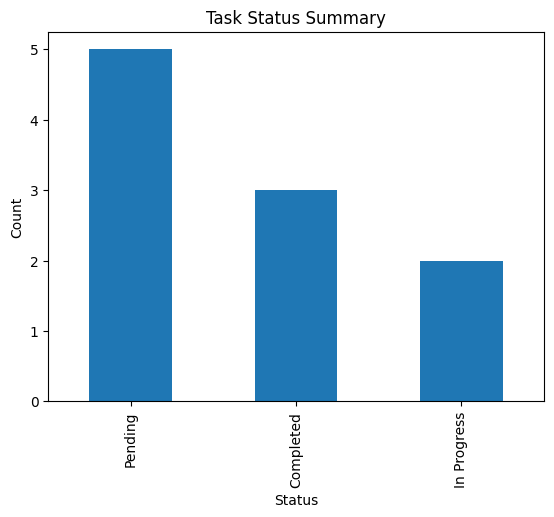

In [11]:
status_counts = df["Status"].value_counts()

status_counts.plot(
    kind="bar"
)

plt.title(
    "Task Status Summary"
)

plt.xlabel(
    "Status"
)

plt.ylabel(
    "Count"
)

plt.show()

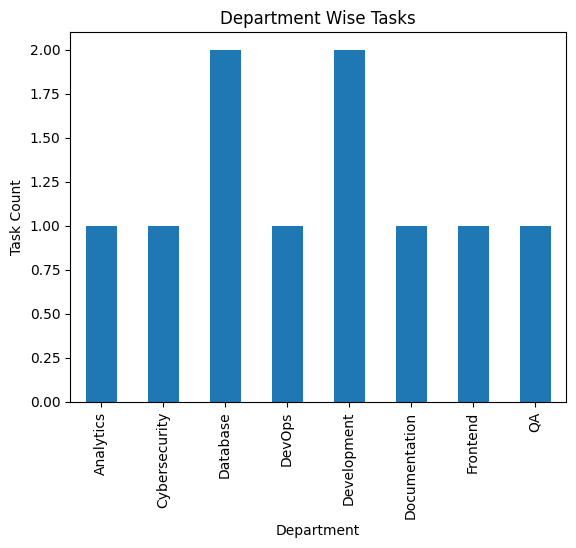

In [12]:
dept_summary.plot(
    kind="bar"
)

plt.title(
    "Department Wise Tasks"
)

plt.xlabel(
    "Department"
)

plt.ylabel(
    "Task Count"
)

plt.show()

In [13]:
high_priority = df[
    df["Priority"]=="High"
]

high_priority

,Task ID,Task Name,Assigned To,Department,Status,Priority,Due Date
0,101,Fix Login Bug,Ravi,Development,Pending,High,2026-06-20
2,103,Update Database,Kiran,Database,Pending,High,2026-06-21
5,106,Optimize Queries,Anjali,Database,Completed,High,2026-06-17
7,108,Security Audit,Deepak,Cybersecurity,In Progress,High,2026-06-25
8,109,Bug Fix Payment Module,Meena,Development,Pending,High,2026-06-20


In [14]:
pending = df.query(
    "Status=='Pending'"
)

pending

,Task ID,Task Name,Assigned To,Department,Status,Priority,Due Date
0,101,Fix Login Bug,Ravi,Development,Pending,High,2026-06-20
2,103,Update Database,Kiran,Database,Pending,High,2026-06-21
4,105,Deploy Website,Arjun,DevOps,Pending,Medium,2026-06-23
6,107,UI Enhancement,Rahul,Frontend,Pending,Medium,2026-06-24
8,109,Bug Fix Payment Module,Meena,Development,Pending,High,2026-06-20


In [15]:
department_report = df.groupby(
    "Department"
).agg(
    Total_Tasks=("Task ID","count")
)

department_report

,Total_Tasks
Department,
Analytics,1
Cybersecurity,1
Database,2
DevOps,1
Development,2
Documentation,1
Frontend,1
QA,1


In [16]:
print("""
Business Insight

1. Daily reporting automated.

2. High priority tasks identified.

3. Department-wise workload analyzed.

4. Manual Excel reporting reduced.

5. Faster management decision making.

6. Improved operational visibility.

""")


Business Insight

1. Daily reporting automated.

2. High priority tasks identified.

3. Department-wise workload analyzed.

4. Manual Excel reporting reduced.

5. Faster management decision making.

6. Improved operational visibility.


